# Solar irradiation and China's solar PV exports
Country-year linear regression · Panels only · 2022–2025

## Question, audience and data
**Question.** Is higher annual solar irradiation associated with greater recorded solar PV export capacity from China, after accounting for population, real GDP per capita and prior-year installed PV capacity?

Each observation is one destination country/economy in one year. The outcome sums recorded **Panels-only** `Capacity (MW)` over the year, then divides by 1,000 for the scatterplots. These are estimated annual panel-export flows in **GW equivalent**. Cells and Wafers are excluded.

The main sample requires Panels records in all 12 distinct months, complete explanatory data, and positive values for all logged variables. Missing monthly records remain unfilled. All four scatterplots use this same regression sample.

Solar irradiation is NASA POWER's actual annual `ALLSKY_SFC_SW_DWN` for 2022–2025. Its 1° grid is intersected with Natural Earth 1:50m country polygons and averaged using intersected land area in equal-area projection EPSG:6933. Annual mean W/m² is converted to kWh/m²/year using 365 days, or 366 in 2024. The regression uses units of **100 kWh/m²/year**.

The notebook rebuilds the Panels-only annual outcome from `data/Processed/panels_processed.csv`. Radiation is joined from the separate **radiation-only** file `data/Processed/solar_radiation_country_year.csv`. Population and real GDP per capita come from matched World Bank data, while previous-year installed solar PV comes from IRENA. Installed capacity for 2021–2024 is matched to exports for 2022–2025.

In [7]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from IPython.display import display, Markdown

# Run from the repository root or the Scripts folder.
root = Path('.')
if not (root / 'data').exists():
    root = Path('..')
panels = pd.read_csv(root / 'data/Processed/panels_processed.csv', parse_dates=['Date'])
panels = panels[(panels['Commodity type'] == 'Panels') &
                (panels['Area type'] == 'Country or economy') &
                panels['Date'].dt.year.between(2022, 2025)].copy()
panels['export_year'] = panels['Date'].dt.year
panels['reporting_month'] = panels['Date'].dt.to_period('M')
assert not panels.duplicated(['Area', 'reporting_month']).any()

annual = panels.groupby(['Area', 'export_year'], as_index=False).agg(
    annual_export_capacity_mw=('Capacity (MW)', 'sum'),
    months_present=('reporting_month', 'nunique'))
annual = annual.rename(columns={'Area': 'ember_destination'})

# Reuse geography and controls; read radiation from the new raw-data workflow.
controls = pd.read_csv(root / 'data/Processed/solar_radiation_country_year_2022_2025.csv')
controls = controls[['ember_destination', 'export_year', 'iso3', 'figure3_region',
    'population', 'real_gdp_pc_2015_usd', 'pv_capacity_year',
    'lag_pv_capacity_mw']]
annual = annual.merge(controls, on=['ember_destination', 'export_year'],
                      how='left', validate='one_to_one')
radiation = pd.read_csv(root / 'data/Processed/solar_radiation_country_year.csv')
annual = annual.merge(radiation[['iso3', 'export_year', 'ghi_kwh_m2_year']],
                      on=['iso3', 'export_year'], how='left', validate='many_to_one')
required = ['annual_export_capacity_mw', 'population', 'real_gdp_pc_2015_usd',
            'lag_pv_capacity_mw', 'ghi_kwh_m2_year']
keep = ((annual['months_present'] == 12) & annual[required].gt(0).all(axis=1) &
        annual['iso3'].notna() & annual['figure3_region'].notna())
sample = annual[keep].copy()

month_counts = panels.groupby('Area')['reporting_month'].nunique()
complete_names = month_counts[month_counts == 48].index
sample['complete_48_months'] = sample['ember_destination'].isin(complete_names)

assert not sample.duplicated(['iso3', 'export_year']).any()
assert sample['months_present'].eq(12).all()
assert (sample['pv_capacity_year'] == sample['export_year'] - 1).all()

sample['capacity_gw'] = sample['annual_export_capacity_mw'] / 1000
sample['log_capacity'] = np.log(sample['annual_export_capacity_mw'])
sample['log_population'] = np.log(sample['population'])
sample['log_gdp_pc'] = np.log(sample['real_gdp_pc_2015_usd'])
sample['log_lag_pv'] = np.log(sample['lag_pv_capacity_mw'])
sample['ghi_per_100'] = sample['ghi_kwh_m2_year'] / 100
print(f"Main sample: {len(sample)} country-years, {sample['iso3'].nunique()} destinations.")

Main sample: 526 country-years, 151 destinations.


## Figure A. Annual radiation–export scatterplots
**Question.** How do recorded exports vary across countries with different solar resources in each year?

The horizontal axis is annual area-weighted irradiation in **kWh/m²/year**. The vertical axis is annual **Panels-only export capacity in GW equivalent**, on a logarithmic scale. Every point is one destination-year; colors indicate regions. Axes and sample rules are identical across the four panels, and the two largest export destinations in each year are labelled.

The black line fits log export capacity to irradiation separately in each year. It is an **unadjusted descriptive fit** and does not control for population, income, installed PV capacity or region. The regression table below provides the adjusted comparison.

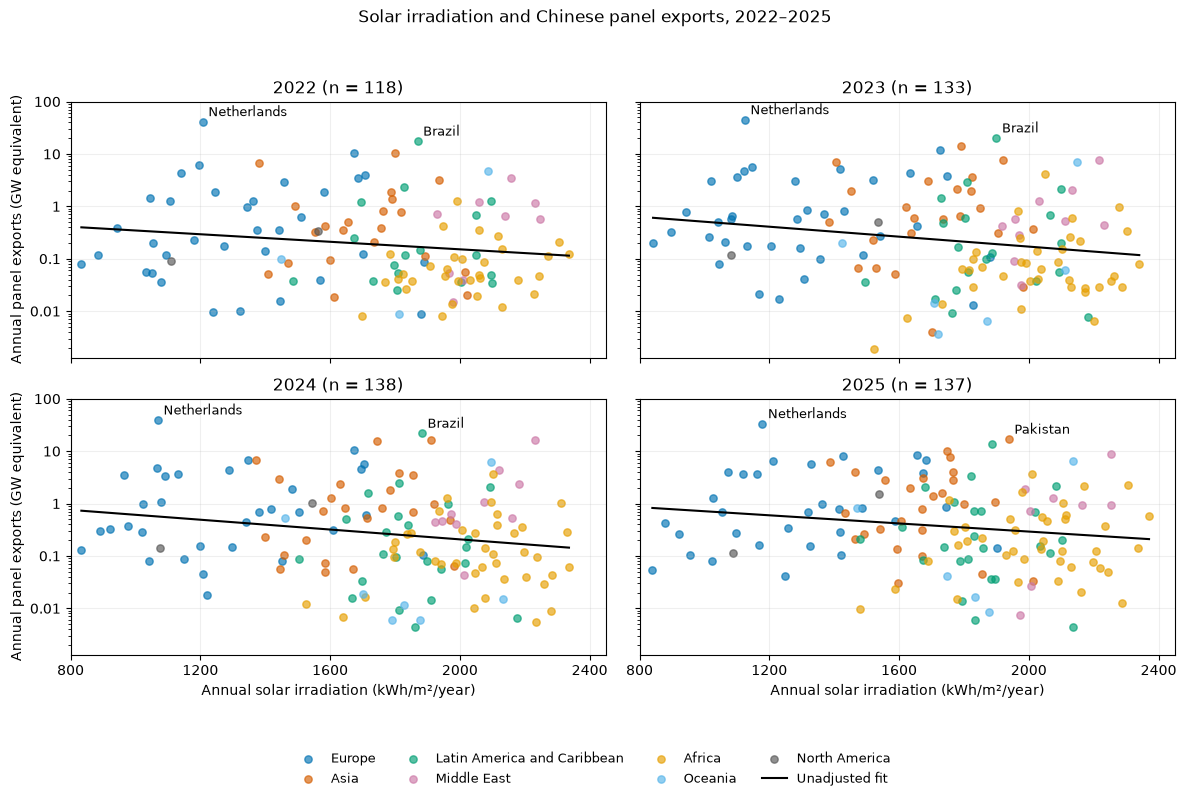

In [8]:
colors = {
    'Europe': '#0072B2',
    'Asia': '#D55E00',
    'Latin America and Caribbean': '#009E73',
    'Middle East': '#CC79A7',
    'Africa': '#E69F00',
    'Oceania': '#56B4E9',
    'North America': '#555555'
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
for ax, year in zip(axes.flat, [2022, 2023, 2024, 2025]):
    d = sample[sample['export_year'] == year]
    for region, color in colors.items():
        r = d[d['figure3_region'] == region]
        ax.scatter(r['ghi_kwh_m2_year'], r['capacity_gw'],
                   color=color, label=region, s=28, alpha=0.65)

    # Simple yearly fit, shown in original GW units on the log y-axis.
    slope, intercept = np.polyfit(d['ghi_kwh_m2_year'], np.log(d['capacity_gw']), 1)
    x = np.linspace(d['ghi_kwh_m2_year'].min(), d['ghi_kwh_m2_year'].max(), 100)
    ax.plot(x, np.exp(intercept + slope * x), color='black', label='Unadjusted fit')

    for _, row in d.nlargest(2, 'capacity_gw').iterrows():
        ax.annotate(row['ember_destination'],
                    (row['ghi_kwh_m2_year'], row['capacity_gw']),
                    xytext=(4, 4), textcoords='offset points', fontsize=9)

    ax.set_title(f"{year} (n = {len(d)})")
    ax.set_yscale('log')
    ax.set_xlim(800, 2450)
    ax.set_ylim(0.0013, 100)
    ax.set_xticks([800, 1200, 1600, 2000, 2400])
    ax.set_yticks([0.01, 0.1, 1, 10, 100], ['0.01', '0.1', '1', '10', '100'])
    ax.grid(alpha=0.2)

for ax in axes[:, 0]:
    ax.set_ylabel('Annual panel exports (GW equivalent)')
for ax in axes[1, :]:
    ax.set_xlabel('Annual solar irradiation (kWh/m²/year)')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, frameon=False, fontsize=9)
fig.suptitle('Solar irradiation and Chinese panel exports, 2022–2025')
fig.tight_layout(rect=[0, 0.10, 1, 0.95])
plt.show()

**Pattern and limitation.** The unadjusted fitted lines slope downward in all four years. The regression below accounts for differences in market characteristics.

Sources: Ember exports, NASA POWER irradiation and the project's country-region mapping.

## Regression method and hypothesis test
We regress **log annual panel-export capacity (MW)** on solar irradiation, controlling for population, real GDP per capita, prior-year installed PV capacity, region and year.

- **H₀:** Solar irradiation has no adjusted association with panel exports (**β = 0**).
- **H₁:** Solar irradiation has an adjusted association with panel exports (**β ≠ 0**).

We use **country-clustered standard errors** and a **5% significance level**. GHI is scaled per **100 kWh/m²/year**.

In [9]:
year_model = smf.ols('log_capacity ~ ghi_per_100 + C(export_year)', data=sample).fit(
    cov_type='cluster', cov_kwds={'groups': sample['iso3']}, use_t=True)

formula = ('log_capacity ~ ghi_per_100 + log_population + log_gdp_pc + '
           'log_lag_pv + C(figure3_region) + C(export_year)')
main_model = smf.ols(formula, data=sample).fit(
    cov_type='cluster', cov_kwds={'groups': sample['iso3']}, use_t=True)

country_formula = formula.replace('C(figure3_region)', 'C(iso3)')
country_model = smf.ols(country_formula, data=sample).fit(
    cov_type='cluster', cov_kwds={'groups': sample['iso3']}, use_t=True)

balanced = sample[sample['complete_48_months']].copy()
balanced_model = smf.ols(formula, data=balanced).fit(
    cov_type='cluster', cov_kwds={'groups': balanced['iso3']}, use_t=True)

models = {'Year adjusted': year_model, 'Main model': main_model,
          'Country + year effects': country_model, 'Complete panel series': balanced_model}
rows = []
for name, model in models.items():
    lower, upper = model.conf_int().loc['ghi_per_100']
    countries = balanced['iso3'].nunique() if name == 'Complete panel series' else sample['iso3'].nunique()
    rows.append({'Model': name, 'N': int(model.nobs), 'Destinations': countries,
                 'GHI coefficient': model.params['ghi_per_100'],
                 'Cluster SE': model.bse['ghi_per_100'],
                 'CI lower': lower, 'CI upper': upper,
                 '95% CI': f'[{lower:.3f}, {upper:.3f}]',
                 'p value': model.pvalues['ghi_per_100'], 'R squared': model.rsquared})
results = pd.DataFrame(rows)
columns = ['Model', 'N', 'Destinations', 'GHI coefficient', 'Cluster SE',
           '95% CI', 'p value', 'R squared']
display(results[columns].style.hide(axis='index').format(precision=4))

Model,N,Destinations,GHI coefficient,Cluster SE,95% CI,p value,R squared
Year adjusted,526,151,-0.0982,0.0402,"[-0.178, -0.019]",0.0157,0.0467
Main model,526,151,0.0912,0.0452,"[0.002, 0.181]",0.0456,0.6553
Country + year effects,526,151,-0.0703,0.1356,"[-0.338, 0.198]",0.6052,0.9265
Complete panel series,433,109,0.0855,0.0503,"[-0.014, 0.185]",0.0920,0.6570


**Table notes.** N counts destination-years; destinations count unique countries/economies. Confidence intervals are country-clustered 95% intervals.

<details>
<summary>Technical details: model specifications and hypothesis test</summary>
<p>The main model is:</p>
<p>ln(Cᵢₜ) = α + β(GHIᵢₜ / 100) + γ₁ ln(Popᵢₜ) + γ₂ ln(GDPpcᵢₜ) + γ₃ ln(PVᵢ,ₜ₋₁) + region effects + year effects + εᵢₜ.</p>
<p>The two-sided test is H₀: β = 0 versus H₁: β ≠ 0. Country-clustered inference uses finite-sample corrections and the Student-t distribution, allowing for unequal error variances and within-country dependence under the model's assumptions.</p>
<ul>
<li><b>Year adjusted:</b> irradiation and year effects.</li>
<li><b>Main model:</b> adds log population, log real GDP per capita, log prior-year installed PV and region effects.</li>
<li><b>Country + year effects:</b> replaces region effects with country effects to examine within-country annual variation.</li>
<li><b>Complete panel series:</b> repeats the main model for destinations with Panels records in all 48 months. The outcome definition is unchanged.</li>
</ul>
<p>The first three models use the same 526 observations. Adding country indicators can raise R² without establishing causation or forecast accuracy.</p>
</details>

In [ ]:
beta = main_model.params['ghi_per_100']
lower, upper = main_model.conf_int().loc['ghi_per_100']
effect = (np.exp(beta) - 1) * 100
effect_lower = (np.exp(lower) - 1) * 100
effect_upper = (np.exp(upper) - 1) * 100

display(Markdown(f"""
### Finding 1. Irradiation is positively associated with exports after adjustment
The main model uses **{len(sample)} destination-years from {sample['iso3'].nunique()} destinations**. Holding population, real GDP per capita, prior-year installed PV, region and year effects constant, an additional **100 kWh/m²/year** is associated with approximately **{effect:.1f}% higher annual estimated panel-export capacity** on the model's geometric scale (95% interval: **{effect_lower:.1f}% to {effect_upper:.1f}%**). The GHI coefficient is **{beta:.4f}**, with **p = {main_model.pvalues['ghi_per_100']:.4f}**. The main specification is just below the 5% significance threshold. This conditional association does not establish a causal effect or a sales forecast.

### Finding 2. The positive association has limited robustness
The year-adjusted coefficient is **{year_model.params['ghi_per_100']:.4f}**, compared with **{beta:.4f}** in the main model, showing that the simple cross-country pattern differs from the adjusted association. In the complete 48-month Panels sample, the coefficient remains positive (**{balanced_model.params['ghi_per_100']:.4f}**, **N = {int(balanced_model.nobs)}**), but **p = {balanced_model.pvalues['ghi_per_100']:.4f}**, so it is not significant at 5%. This loss of significance alone does not demonstrate that the two coefficients differ. The country-and-year-effects estimate is **{country_model.params['ghi_per_100']:.4f}**, with **p = {country_model.pvalues['ghi_per_100']:.4f}**. Evidence for an association between within-country annual irradiation changes and exports is therefore weak over these four years. Non-significance does not establish a zero association.

**For exporters.** Solar resource is one factor to investigate alongside market size, existing deployment, local manufacturing, policy and logistics. This evidence supports further market research, while it is insufficient to choose shipment timing or predict profit from radiation alone.
"""))


### Finding 1. Irradiation is positively associated with exports after adjustment
The main model uses **526 destination-years from 151 destinations**. Holding population, real GDP per capita, prior-year installed PV, region and year effects constant, an additional **100 kWh/m²/year** is associated with approximately **9.5% higher annual estimated panel-export capacity** on the model's geometric scale (95% interval: **0.2% to 19.8%**). The GHI coefficient is **0.0912**, with **p = 0.0456**. The main specification is just below the 5% significance threshold. This conditional association does not establish a causal effect or a sales forecast.

### Finding 2. The positive association has limited robustness
The year-adjusted coefficient is **-0.0982**, compared with **0.0912** in the main model, showing that the simple cross-country pattern differs from the adjusted association. In the complete 48-month Panels sample, the coefficient remains positive (**0.0855**, **N = 433**), but **p = 0.0920**, so it is not significant at 5%. This loss of significance alone does not demonstrate that the two coefficients differ. The country-and-year-effects estimate is **-0.0703**, with **p = 0.6052**. Evidence for an association between within-country annual irradiation changes and exports is therefore weak over these four years. Non-significance does not establish a zero association.

**For exporters.** Solar resource is one factor to investigate alongside market size, existing deployment, local manufacturing, policy and logistics. This evidence supports further market research, while it is insufficient to choose shipment timing or predict profit from radiation alone.


## Figure B. Model comparison and residual diagnostic
**Questions.** Does the estimated irradiation relationship change with the specification, and do the main-model errors show patterns?

The left panel shows irradiation coefficients per **100 kWh/m²/year** and country-clustered 95% confidence intervals. The zero line helps compare the estimates and their uncertainty. The right panel plots the main-model residual against fitted log capacity; both axes use log-capacity units, not GW. A residual is the observed log capacity minus the fitted value.

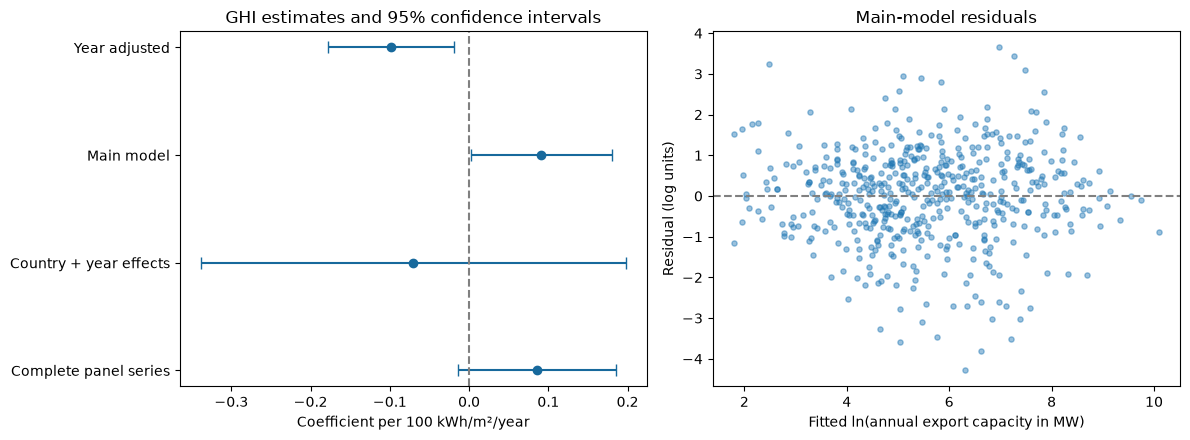

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
positions = np.arange(len(results))
axes[0].errorbar(results['GHI coefficient'], positions,
    xerr=[results['GHI coefficient'] - results['CI lower'],
          results['CI upper'] - results['GHI coefficient']],
    fmt='o', capsize=4, color='#17699c')
axes[0].axvline(0, color='gray', linestyle='--')
axes[0].set_yticks(positions, results['Model'])
axes[0].invert_yaxis()
axes[0].set_xlabel('Coefficient per 100 kWh/m²/year')
axes[0].set_title('GHI estimates and 95% confidence intervals')

axes[1].scatter(main_model.fittedvalues, main_model.resid, s=14, alpha=0.45)
axes[1].axhline(0, color='gray', linestyle='--')
axes[1].set_xlabel('Fitted ln(annual export capacity in MW)')
axes[1].set_ylabel('Residual (log units)')
axes[1].set_title('Main-model residuals')
fig.tight_layout()
plt.show()

**Interpretation and limitation.** The coefficient plot makes the change in sign and the wide country-effects interval visible. The residual plot is a visual check for curvature, unusual observations and changing error spread. It is not a pass/fail test. Country-clustered inference accounts for within-country error dependence and unequal variances under its assumptions; it does not resolve omitted variables, an incorrect functional form or measurement error. The models describe associations rather than a validated prediction rule.

## Limitations and reproducibility
- **Product and outcome scope:** This analysis includes Panels only. Annual panel exports can be held in inventory, re-exported or installed later. The outcome is not the destination's installed capacity, final demand or profit.

- **Estimated capacity:** Ember estimates panel capacity using export value and monthly reference prices. Reference assumptions affect the outcome; export value and estimated capacity are not independent measures.

- **Spatial measurement:** Country irradiation is area-weighted at 1° resolution and does not reflect the specific locations of PV systems. Boundaries, small islands and overseas territories introduce approximation and matching exclusions.

- **Sample selection:** Complete-case and monthly-coverage rules exclude some destinations. Missing monthly exports are not set to zero. The complete-series comparison excludes new and intermittent Panels trade relationships.

- **Interpretation:** Four years provide limited within-country variation. Re-exports, domestic manufacturing, tariffs, policy and logistics can affect shipments. Controlling for installed PV estimates an association conditional on the existing market base; it does not capture every pathway linking solar resource and exports.
